# Unidad 4 — Aplicaciones económicas avanzadas

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 23-11-2026 (2 horas, después de cerrar la Unidad 3) · Contenidos 4.1 a 4.5

Las Unidades 1 a 3 respondieron "¿cómo funciona cada modelo?". Esta unidad responde otra pregunta: **¿sirve para decidir?** Un modelo es útil para una institución cuando alguien puede tomar una decisión mejor con él que sin él, y sabe cuánto confiar en lo que dice.

## Objetivos

Al terminar deberías poder:

- plantear un problema económico como un problema de modelos: **qué se predice y contra qué se compara**;
- detectar **anomalías** en series económicas y explicar por qué la mayoría de las alertas pueden ser falsas;
- **segmentar** clientes e interpretar los grupos en términos de negocio;
- evaluar un modelo de riesgo en el **Test**, con su **incertidumbre** y con el **costo de cada error**;
- comunicar el resultado y sus **limitaciones** en una ficha de una página.

## Ruta de la unidad

| Parte | Contenido | Qué haremos | Herramienta |
|---|---|---|---|
| 1 | 4.1 | Variable objetivo y línea base: ¿una red pronostica mejor la inflación que el PM12? | Keras, tabla de rezagos del Módulo 5 |
| 2 | 4.2 | Anomalías en la economía ecuatoriana y falsos positivos | regla de las 3 desviaciones, `IsolationForest`, Bayes |
| 3 | 4.3 | Segmentación de clientes e interpretación | `KMeans` |
| 4 | 4.4 | El Test, una sola vez: métricas, incertidumbre y costos | remuestreo (*bootstrap*) |
| 5 | 4.5 | Ficha ejecutiva y limitaciones | — |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow

In [2]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /home/claude/m6/datos


# 0. Librerías

Nada nuevo salvo `IsolationForest` (detección de anomalías). `KMeans` es el del Módulo 3 y Keras, el de la Unidad 3.

In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error

import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')

In [4]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')

datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')

# X: lo que sabemos del cliente en septiembre · y: si no pagó en octubre (1 = impago)
X = datos.drop(columns=['id', 'impago'])
y = datos['impago']

# La misma partición en todo el módulo (misma semilla): 60 % Train, 20 % Validation, 20 % Test.
# stratify=y mantiene el 22 % de impagos en las tres partes.
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print('Train:', X_train.shape, '· Validation:', X_val.shape, '· Test:', X_test.shape)
print('Tasa de impago -> Train:', round(y_train.mean(), 3), '· Validation:', round(y_val.mean(), 3), '· Test:', round(y_test.mean(), 3))

Train: (18000, 23) · Validation: (6000, 23) · Test: (6000, 23)
Tasa de impago -> Train: 0.221 · Validation: 0.221 · Test: 0.221


# 1. Elegir la variable objetivo y la línea base (4.1)

## 1.1 Tres preguntas antes de abrir Python

Todo proyecto de modelos empieza por traducir una pregunta de negocio a tres definiciones.

| Pregunta | Significado | Error típico |
|---|---|---|
| **¿Qué quiero predecir?** (variable objetivo) | una columna concreta, medida en una fecha concreta | elegir algo que no se puede medir o que se conoce demasiado tarde |
| **¿Con qué información?** (predictores) | solo lo que se sabe **antes** de decidir | fuga de información: usar datos del futuro |
| **¿Contra qué comparo?** (línea base) | la regla más simple que alguien usaría hoy | no tener línea base y declarar "bueno" un modelo que no mejora nada |

Los dos casos del diplomado, puestos en esa tabla:

| | Impago de tarjetas (Módulo 6) | Inflación mensual (Módulo 5) |
|---|---|---|
| Decisión | ¿a qué clientes llamo antes de octubre? | ¿qué inflación uso en la programación del próximo mes? |
| Objetivo | `impago` en octubre (sí o no) | variación mensual del IPC (un número) |
| Predictores | perfil, atrasos, facturas y pagos hasta septiembre | la propia inflación de los meses anteriores |
| Tipo de problema | clasificación | pronóstico (regresión) |
| Línea base | regla del atraso (2+ meses) | promedio móvil de 12 meses (PM12) |
| Métrica | AUC, Brier, costo | MAE |
| Partición | aleatoria (los clientes no tienen orden) | **por fecha** (nunca al azar) |

## 1.2 El objetivo cambia el modelo: una red para pronosticar la inflación

En la Unidad 3, la red **clasificaba**. Para **pronosticar un número** solo cambian dos cosas:

| | Clasificación | Regresión |
|---|---|---|
| Activación de la salida | sigmoide (una probabilidad) | **lineal** (cualquier número) |
| Pérdida | entropía cruzada | **error absoluto medio** (MAE) o cuadrático |

Usamos la misma tabla de rezagos del Día 4 del Módulo 5 y la misma partición: entrenar hasta diciembre de 2024, Test de enero de 2025 a agosto de 2026. Las cifras de referencia de ese día: **PM12 0.286**, mejor ARIMA 0.308, Random Forest 0.313.

In [5]:
inflacion = series['ipc_var_mensual'].loc['2005':].dropna()

# Tabla de aprendizaje supervisado del Módulo 5 (primero shift, después rolling)
tabla = pd.DataFrame({'objetivo': inflacion})
for k in [1, 2, 3, 6, 12]:
    tabla[f'rezago_{k}'] = inflacion.shift(k)
tabla['media_3'] = inflacion.shift(1).rolling(3).mean()
tabla['media_12'] = inflacion.shift(1).rolling(12).mean()
tabla['mes'] = tabla.index.month
tabla = tabla.dropna()

columnas = tabla.columns.drop('objetivo')
entrena, prueba = tabla.loc[:'2024-12'], tabla.loc['2025-01':]
print('Meses para entrenar:', len(entrena), '· meses de Test:', len(prueba))

# Normalizamos con la media y la desviación de los meses de entrenamiento
escala_inflacion = StandardScaler().fit(entrena[columnas])
A, B = escala_inflacion.transform(entrena[columnas]), escala_inflacion.transform(prueba[columnas])

# Red de regresión: una capa oculta pequeña y salida LINEAL
keras.utils.set_random_seed(42)
red_inflacion = keras.Sequential([
    keras.Input(shape=(len(columnas),)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1),                                  # sin activación: salida lineal
])
red_inflacion.compile(optimizer=keras.optimizers.Adam(0.01), loss='mae')
historia = red_inflacion.fit(A, entrena['objetivo'], epochs=150, batch_size=32, verbose=0)

bosque_inflacion = RandomForestRegressor(n_estimators=100, max_depth=5, max_features=0.5, random_state=42).fit(entrena[columnas], entrena['objetivo'])

pronosticos = pd.DataFrame({
    'Promedio móvil 12 (línea base)': prueba['media_12'],
    'Ingenuo (mes anterior)': prueba['rezago_1'],
    'Random Forest (M5, Día 4)': bosque_inflacion.predict(prueba[columnas]),
    'Red neuronal (8 neuronas)': red_inflacion.predict(B, verbose=0).ravel(),
}, index=prueba.index)

mae_inflacion = pronosticos.apply(lambda columna: mean_absolute_error(prueba['objetivo'], columna)).sort_values()
print('MAE de la red en sus propios meses de entrenamiento:', round(mean_absolute_error(entrena['objetivo'], red_inflacion.predict(A, verbose=0).ravel()), 3))
mae_inflacion.round(3).to_frame('MAE en Test')

Meses para entrenar: 228 · meses de Test: 20


MAE de la red en sus propios meses de entrenamiento: 0.178


,MAE en Test
Promedio móvil 12 (línea base),0.286
"Random Forest (M5, Día 4)",0.313
Red neuronal (8 neuronas),0.341
Ingenuo (mes anterior),0.478


**Lectura:**

| Modelo | MAE en Test |
|---|---:|
| Promedio móvil 12 | **0.286** |
| Random Forest | 0.313 |
| Red neuronal | 0.341 |
| Ingenuo | 0.478 |

- La red queda **detrás del Random Forest y del PM12**. Y mira su error en los meses con los que entrenó: 0.18. Con 228 meses y más de 80 parámetros, la red memoriza: es la curva de sobreajuste de la Unidad 3, con muy pocos datos.
- **El problema define el modelo, no al revés.** Una red neuronal necesita muchos datos; una serie mensual de 20 años tiene 240. Para la inflación mensual del Ecuador, la línea base sigue siendo lo mejor que tenemos, como concluimos en el Módulo 5.

**Regla práctica para elegir modelo según el problema:**

| Situación | Punto de partida razonable |
|---|---|
| Serie mensual corta (cientos de meses) | líneas base y ARIMA; Machine Learning solo si aporta variables externas |
| Tabla con miles de filas y decenas de columnas | Random Forest o boosting |
| Hace falta explicar cada decisión | árbol pequeño o regresión logística |
| Hace falta la incertidumbre | modelos bayesianos o intervalos por remuestreo |
| Imágenes, texto, millones de registros | redes neuronales |

# 2. Anomalías y señales de alerta (4.2)

## 2.1 ¿Qué es una anomalía?

Una **anomalía** es una observación que no se parece al resto: una transacción rarísima, un banco cuyos indicadores se salen del patrón, un mes en que la economía se comportó de forma extrema.

Diferencia clave con todo lo anterior: **no hay columna objetivo**. Nadie marcó qué meses son "anómalos". Es aprendizaje **no supervisado**, como el clustering del Módulo 3.

## 2.2 Los datos: cinco indicadores mensuales del Ecuador

Para cada mes desde 2005 calculamos cinco **cambios** (el velocímetro, no el odómetro):

In [6]:
periodo = series.loc['2004-12':'2026-08']

indicadores = pd.DataFrame({
    'inflacion': periodo['ipc_var_mensual'],                                    # % mensual
    'riesgo_cambio': periodo['riesgo_pais_pb'].diff(),                          # puntos básicos
    'crudo_var': periodo['precio_wti_usd'].pct_change() * 100,                  # % mensual
    'exportaciones_var': periodo['exportaciones_fob_musd'].pct_change() * 100,  # % mensual
    'reservas_var': periodo['reservas_internacionales_musd'].pct_change() * 100 # % mensual
}).dropna()

print('Meses:', len(indicadores), '· desde', indicadores.index.min().date(), 'hasta', indicadores.index.max().date())
indicadores.describe().round(2).T[['mean', 'std', 'min', 'max']]

Meses: 260 · desde 2005-01-01 hasta 2026-08-01


,mean,std,min,max
inflacion,0.21,0.37,-0.99,1.52
riesgo_cambio,-1.08,285.46,-1305.15,2491.70
crudo_var,0.80,10.57,-44.73,72.94
exportaciones_var,1.14,9.80,-32.68,39.01
reservas_var,2.21,18.31,-39.33,132.82


## 2.3 Método 1: la regla de las tres desviaciones

La forma más simple: un valor es anómalo si está a **más de 3 desviaciones estándar** de su media. Para compararlo entre indicadores usamos el valor escalado (la misma $z$ de KNN):

$$z = \frac{x - \text{media}}{\text{desviación}}$$

**A mano:** en marzo de 2020 el riesgo país subió 2 492 puntos en un mes. La media del cambio mensual es −1 y la desviación 285:

$$z = \frac{2\,492 - (-1)}{285} \approx 8.7$$

Casi 9 desviaciones: muy por encima de 3.

In [7]:
escalados = (indicadores - indicadores.mean()) / indicadores.std()

# Un mes es anómalo si ALGÚN indicador supera las 3 desviaciones (hacia arriba o hacia abajo)
anomalo_z = (escalados.abs() > 3).any(axis=1)
print('Meses anómalos con la regla de 3 desviaciones:', anomalo_z.sum(), 'de', len(indicadores))

# ¿Qué indicador disparó cada alerta?
detalle = escalados[anomalo_z].round(1)
detalle['disparado por'] = (escalados[anomalo_z].abs() > 3).apply(lambda fila: ', '.join(fila.index[fila]), axis=1)
detalle.index = detalle.index.strftime('%Y-%m')
detalle

Meses anómalos con la regla de 3 desviaciones: 19 de 260


,inflacion,riesgo_cambio,crudo_var,exportaciones_var,reservas_var,disparado por
fecha,,,,,,
2008-03,3.4,0.1,0.9,-1.2,0.1,inflacion
2008-04,3.5,-0.2,0.5,1.7,1.8,inflacion
2008-10,-0.5,4.0,-2.6,-1.7,-0.3,riesgo_cambio
2008-11,-1.0,6.8,-2.5,-2.1,-0.3,riesgo_cambio
2009-07,-0.8,-4.4,-0.8,0.5,0.9,riesgo_cambio
2014-05,-0.7,-0.3,-0.1,3.9,0.6,exportaciones_var
2016-06,0.4,-0.1,0.3,-0.2,3.1,reservas_var
2017-06,-2.1,0.2,-0.7,-0.8,3.2,reservas_var
2017-10,-1.0,-0.2,0.3,0.4,5.5,reservas_var


**Lectura:** la regla marca 19 de los 260 meses. Se reconocen los grandes episodios: el alza de precios de **marzo y abril de 2008** (inflación a más de 3 desviaciones), **la crisis financiera de 2008** (octubre y noviembre: el riesgo país sube más de 1 000 puntos en un mes), **la pandemia de 2020** (de marzo a junio: riesgo país, crudo y exportaciones) y saltos puntuales de las reservas.

La regla mira **cada indicador por separado**. No ve los meses en que nada es extremo por sí solo, pero la **combinación** es rara.

## 2.4 Método 2: Isolation Forest

**La idea:** un bosque de árboles que hacen cortes **al azar**. Un dato raro queda aislado con muy pocos cortes; un dato normal, rodeado de datos parecidos, necesita muchos.

Piensa en el juego de "adivina quién": a un personaje con sombrero verde y parche en el ojo lo identificas con dos preguntas; a uno de aspecto común, con diez. **Cuantas menos preguntas hacen falta para aislar un dato, más anómalo es.**

Hay que decirle qué fracción de datos esperamos que sean anómalos (`contamination`). Elegimos 5 %: 13 meses.

In [8]:
bosque_aislamiento = IsolationForest(n_estimators=300, contamination=0.05, random_state=42).fit(escalados)

puntaje = pd.Series(-bosque_aislamiento.score_samples(escalados), index=indicadores.index)   # más alto = más raro
anomalo_bosque = pd.Series(bosque_aislamiento.predict(escalados) == -1, index=indicadores.index)

resumen = indicadores[anomalo_bosque].round(1)
resumen['puntaje'] = puntaje[anomalo_bosque].round(3)
resumen['también regla 3 desv.'] = anomalo_z[anomalo_bosque]
resumen = resumen.sort_values('puntaje', ascending=False)
resumen.index = resumen.index.strftime('%Y-%m')
resumen

,inflacion,riesgo_cambio,crudo_var,exportaciones_var,reservas_var,puntaje,también regla 3 desv.
fecha,,,,,,,
2020-04,1.0,1091.0,-44.7,-32.7,43.7,0.731,True
2020-03,0.2,2491.7,-40.9,-11.7,-39.3,0.709,True
2020-05,-0.3,-689.8,72.9,31.0,18.9,0.692,True
2020-06,-0.6,-900.8,34.1,13.0,-21.6,0.632,True
2008-11,-0.2,1946.5,-25.2,-19.0,-4.2,0.626,True
2018-01,0.2,-18.1,9.9,0.8,132.8,0.583,True
2009-03,1.1,-131.3,23.0,24.1,-18.8,0.571,False
2008-04,1.5,-59.9,6.3,18.0,35.1,0.560,True
2026-03,0.1,18.7,41.5,28.0,-8.9,0.552,True


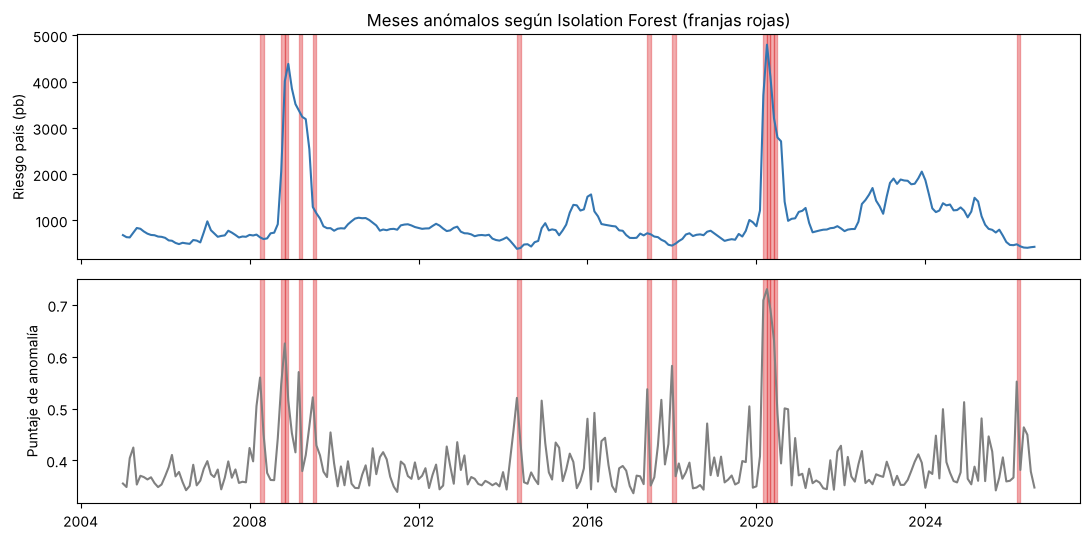

In [9]:
fig, ejes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ejes[0].plot(periodo['riesgo_pais_pb'].loc['2005':], color='#3476B1')
ejes[0].set_ylabel('Riesgo país (pb)'); ejes[0].set_title('Meses anómalos según Isolation Forest (franjas rojas)')
ejes[1].plot(puntaje, color='gray'); ejes[1].set_ylabel('Puntaje de anomalía')
for fecha in indicadores.index[anomalo_bosque]:
    for ax in ejes:
        ax.axvspan(fecha, fecha + pd.offsets.MonthBegin(1), color='#DA181E', alpha=0.35)
plt.tight_layout(); plt.show()

**Lectura:**

- Los cuatro meses más anómalos son **marzo, abril, mayo y junio de 2020**: la pandemia, con riesgo país, crudo, exportaciones y reservas moviéndose a la vez como nunca antes.
- Después aparecen **noviembre y octubre de 2008** (la crisis financiera internacional, con el riesgo país subiendo más de 1 000 puntos por mes), **enero de 2018** (las reservas más que se duplican) y **marzo de 2009**.
- De los 13 meses marcados, 12 también los marcaba la regla de las 3 desviaciones. Los dos métodos **coinciden en lo importante**; el bosque ordena además los meses de más a menos raro.

**Cuidado con la interpretación:** el modelo dice "este mes es raro", no "este mes es una crisis". Un salto de 133 % en las reservas (enero de 2018) es anómalo, pero no es una crisis: es más probable que refleje una entrada grande de financiamiento externo, y eso hay que verificarlo en las fuentes, no en el modelo. **Una anomalía es una pregunta para el analista, no una respuesta.**

## 2.5 Falsos positivos: el problema de toda alerta temprana

Supongamos que una institución monta un sistema de alerta de crisis con estas características (son supuestos para el ejercicio):

- las crisis verdaderas son raras: ocurren en el **2 %** de los meses (**tasa base**);
- cuando hay crisis, el sistema la detecta el **90 %** de las veces (sensibilidad);
- cuando **no** hay crisis, el sistema suena igual el **5 %** de las veces (falsa alarma).

**Suena la alerta. ¿Cuál es la probabilidad de que haya una crisis?**

**A mano, con 1 000 meses** (Unidad 2):

- 20 meses de crisis → el sistema detecta 18.
- 980 meses normales → el sistema suena en 49.
- Alertas totales: 18 + 49 = 67. Crisis de verdad: 18.

$$P(\text{crisis} \mid \text{alerta}) = \frac{18}{67} \approx 0.27$$

**Casi tres de cada cuatro alertas son falsas**, con un sistema que detecta el 90 % de las crisis y solo se equivoca el 5 % de las veces.

In [10]:
def bayes(prior, p_dato_si_cierta, p_dato_si_falsa):
    """Teorema de Bayes (Unidad 2)."""
    return p_dato_si_cierta * prior / (p_dato_si_cierta * prior + p_dato_si_falsa * (1 - prior))

print('P(crisis | alerta) con tasa base 2 %:', round(bayes(0.02, 0.90, 0.05), 3))

# ¿Y si bajamos la tasa de falsas alarmas del sistema?
for falsa_alarma in [0.10, 0.05, 0.01]:
    print(f'  falsa alarma = {falsa_alarma:.0%}  ->  P(crisis | alerta) = {bayes(0.02, 0.90, falsa_alarma):.2f}')

# Una segunda alerta INDEPENDIENTE (otro sistema, con otros datos) sobre el mismo mes
print('Después de dos alertas independientes:', round(bayes(bayes(0.02, 0.90, 0.05), 0.90, 0.05), 3))

P(crisis | alerta) con tasa base 2 %: 0.269
  falsa alarma = 10%  ->  P(crisis | alerta) = 0.16
  falsa alarma = 5%  ->  P(crisis | alerta) = 0.27
  falsa alarma = 1%  ->  P(crisis | alerta) = 0.65
Después de dos alertas independientes: 0.869


**Lectura:**

- Con sucesos raros, lo que más importa es la **tasa de falsas alarmas**: bajarla de 5 % a 1 % sube la credibilidad de la alerta de 0.27 a 0.65.
- **Una segunda señal independiente** lleva la probabilidad a 0.87. Por eso los sistemas de alerta serios no actúan con una señal: la usan para **pedir una revisión**, y actúan cuando varias fuentes distintas coinciden. Recuerda la Unidad 2: tienen que ser de verdad independientes, no la misma noticia contada dos veces.

**Para decisiones institucionales:** una alerta es el inicio de un análisis. Un sistema que suena demasiado deja de ser escuchado.

# 3. Segmentación y clasificación económica (4.3)

## 3.1 Segmentar para entender

**Segmentar** es agrupar clientes parecidos **sin usar la variable objetivo**, para entender qué tipos de clientes hay. Es el K-Means del Módulo 3. La pregunta de hoy no es cómo funciona, sino **cómo se interpreta**.

Primero construimos un **perfil** de pocas variables con significado de negocio (ingeniería de variables, Módulo 3, Día 5):

| Variable | Cálculo | Qué describe |
|---|---|---|
| `limite_miles` | cupo / 1 000 | tamaño del cliente |
| `edad` | — | etapa de vida |
| `uso_cupo` | factura promedio / cupo | qué tan "copada" está la tarjeta |
| `pago_sobre_factura` | pagos de 6 meses / facturas de 6 meses | si paga todo o solo el mínimo |
| `meses_con_atraso` | meses con atraso, de los últimos 6 | historial de atrasos |

In [11]:
def perfil(tabla):
    """Cinco variables de negocio a partir de las 23 columnas originales."""
    facturas = [c for c in tabla if c.startswith('factura')]
    pagos = [c for c in tabla if c.startswith('pago')]
    atrasos = [c for c in tabla if c.startswith('atraso')]
    return pd.DataFrame({
        'limite_miles': tabla['limite_credito'] / 1000,
        'edad': tabla['edad'],
        'uso_cupo': (tabla[facturas].mean(axis=1) / tabla['limite_credito']).clip(0, 1.5),
        'pago_sobre_factura': (tabla[pagos].sum(axis=1) / tabla[facturas].sum(axis=1).clip(lower=1)).clip(0, 2),
        'meses_con_atraso': (tabla[atrasos] >= 1).sum(axis=1),
    })

perfil_train = perfil(X_train)

# K-Means mide distancias: escalamos (Unidad 1)
escala_perfil = StandardScaler().fit(perfil_train)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(escala_perfil.transform(perfil_train))

# Interpretación: el promedio de cada variable en cada segmento (en sus unidades originales)
segmentos = perfil_train.groupby(kmeans.labels_).mean().round(2)
segmentos['clientes'] = np.bincount(kmeans.labels_)
# Solo AHORA miramos el objetivo: la tasa de impago de cada segmento
segmentos['tasa_impago'] = y_train.groupby(kmeans.labels_).mean().round(3).values
segmentos.index.name = 'segmento'
segmentos.sort_values('tasa_impago')

,limite_miles,edad,uso_cupo,pago_sobre_factura,meses_con_atraso,clientes,tasa_impago
segmento,,,,,,,
0,255.44,36.67,0.06,0.76,0.31,7239,0.146
1,113.34,34.44,0.57,0.10,0.35,8577,0.186
2,87.69,34.89,0.61,0.08,4.52,2184,0.608


**Cómo se interpreta un segmento:** se mira la fila y se le pone un **nombre de negocio**.

| Segmento | Rasgos | Nombre | Tasa de impago |
|---|---|---|---:|
| Cupo alto (≈ 255 mil), usa el 6 % del cupo, casi sin atrasos | no depende de la tarjeta | **"Holgados"** | 15 % |
| Cupo medio (≈ 113 mil), usa el 57 % del cupo, casi sin atrasos | usa mucho la tarjeta, pero cumple | **"Usuarios intensivos"** | 19 % |
| Cupo bajo (≈ 88 mil), usa el 61 % del cupo, **4.5 de 6 meses con atraso** | atraso crónico | **"En mora recurrente"** | **61 %** |

K-Means **no vio** la columna `impago`, y aun así encontró un grupo con el triple de riesgo. Eso indica que el riesgo está escrito en el comportamiento.

**Para qué sirve si ya tenemos un clasificador:**

- **Comunicar.** "El 12 % de los clientes está en mora recurrente y concentra un tercio de los impagos" se entiende sin saber qué es un AUC.
- **Diseñar acciones distintas por grupo**: un plan de pagos para unos, un aumento de cupo para otros.
- **Vigilar cambios.** Si el segmento de mora recurrente pasa del 12 % al 18 % de la cartera, algo cambió en la economía, aunque el modelo siga funcionando igual.

**Segmentar describe; clasificar predice.** Se complementan.

# 4. Riesgo económico: el Test, la incertidumbre y el costo de cada error (4.4)

Llegó el momento que anunciamos en la Unidad 1: **abrir el Test, una sola vez**, con los modelos del módulo.

## 4.1 Los modelos del módulo

Se entrenan con Train, exactamente con la configuración de cada unidad. Ninguno ha visto el Test.

| Modelo | Unidad |
|---|---|
| Regla del atraso (línea base) | 1 |
| Regresión logística | 2 y 3 (una neurona) |
| Naive Bayes | 2 |
| Random Forest | 1 |
| Boosting | 1 |
| Red neuronal 32 + 16 con dropout | 3 |

In [12]:
modelos = {
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
}

prob_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    prob_test[nombre] = modelo.predict_proba(X_test)[:, 1]

# La red de la Unidad 3: si existe el archivo guardado, se carga; si no, se entrena de nuevo (unos 30 segundos)
escalador = StandardScaler().fit(X_train)
archivo_red = Path('resultados_modulo6') / 'red_impago.keras'
if archivo_red.exists():
    red = keras.models.load_model(archivo_red)
    print('Red cargada desde', archivo_red)
else:
    keras.utils.set_random_seed(42)
    red = keras.Sequential([keras.Input(shape=(X_train.shape[1],)),
                            layers.Dense(32, activation='relu'), layers.Dropout(0.3),
                            layers.Dense(16, activation='relu'), layers.Dropout(0.3),
                            layers.Dense(1, activation='sigmoid')])
    red.compile(optimizer=keras.optimizers.Adam(0.001), loss='binary_crossentropy')
    parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    red.fit(escalador.transform(X_train), y_train, validation_data=(escalador.transform(X_val), y_val),
            epochs=100, batch_size=128, verbose=0, callbacks=[parada])
    print('Red entrenada de nuevo')
prob_test['Red neuronal'] = red.predict(escalador.transform(X_test), verbose=0).ravel()

Red cargada desde resultados_modulo6/red_impago.keras


## 4.2 El Test

Las tres miradas de la Unidad 2: ¿ordena bien? (AUC), ¿probabilidades creíbles? (Brier), ¿cuánto cuesta decidir con él?

Para el costo usamos la regla de la Unidad 2: llamar cuesta 1, un impago no gestionado cuesta 5, se llama si la probabilidad supera 0.20.

In [13]:
def costo_total(prob, umbral=0.20, costo_llamada=1, costo_impago=5):
    llamar = prob > umbral
    return llamar.sum() * costo_llamada + ((~llamar) & (y_test.values == 1)).sum() * costo_impago

regla_test = (X_test['atraso_sep'] >= 2).astype(float).values

filas = [{'Modelo': 'Regla del atraso (línea base)', 'AUC': roc_auc_score(y_test, X_test['atraso_sep']), 'Brier': np.nan,
          'Costo': costo_total(regla_test, 0.5), 'Clientes llamados': int(regla_test.sum()),
          'Impagos alcanzados': regla_test[y_test.values == 1].mean()}]
for nombre, prob in prob_test.items():
    filas.append({'Modelo': nombre, 'AUC': roc_auc_score(y_test, prob), 'Brier': brier_score_loss(y_test, prob),
                  'Costo': costo_total(prob), 'Clientes llamados': int((prob > 0.20).sum()),
                  'Impagos alcanzados': (prob > 0.20)[y_test.values == 1].mean()})

print('Referencias de costo -> no llamar a nadie:', int(y_test.sum()) * 5, '· llamar a todos:', len(y_test))
tabla_test = pd.DataFrame(filas).set_index('Modelo').sort_values('Costo')
tabla_test.round(3)

Referencias de costo -> no llamar a nadie: 6635 · llamar a todos: 6000


,AUC,Brier,Costo,Clientes llamados,Impagos alcanzados
Modelo,,,,,
Boosting,0.778,0.136,4265,1955,0.652
Red neuronal,0.775,0.137,4384,2154,0.664
Random Forest,0.768,0.137,4386,2211,0.672
Regresión logística,0.709,0.146,4965,2825,0.677
Regla del atraso (línea base),0.676,NaN,5076,636,0.331
Naive Bayes,0.723,0.223,5105,3870,0.814


**Lectura del Test:**

| Modelo | AUC | Brier | Costo | Comentario |
|---|---:|---:|---:|---|
| Boosting | 0.778 | 0.136 | 4 265 | el mejor en el Test |
| Red neuronal | 0.775 | 0.137 | 4 384 | prácticamente igual |
| Random Forest | 0.768 | 0.137 | 4 386 | el ganador de Validation queda tercero |
| Regresión logística | 0.709 | 0.146 | 4 965 | una sola neurona |
| Regla del atraso | 0.676 | — | 5 076 | la línea base |
| Naive Bayes | 0.723 | 0.223 | 5 105 | ordena aceptablemente, pero sus probabilidades exageradas lo hacen **más caro que la regla** |

1. **Los tres modelos avanzados superan con claridad a la línea base**: entre 14 % y 16 % menos de costo, y alcanzan a dos de cada tres impagos donde la regla alcanza a uno de cada tres.
2. **Entre los tres hay muy poca diferencia** (0.01 de AUC, 3 % de costo).
3. **El orden cambió respecto a Validation.** Allí el Random Forest iba primero (0.783) y aquí queda tercero (0.768). No es un error: es lo que pasa cuando los modelos están tan cerca. La misma lección del Módulo 5.
4. **Naive Bayes** confirma la Unidad 2: con el umbral de los costos llama a 3 870 clientes, casi dos de cada tres.

**¿Y ahora cambiamos de modelo?** No. La elección se hace **con Validation** y el Test solo **informa** cuánto rinde lo elegido. Si eligiéramos al ganador del Test, el Test dejaría de ser una evaluación honesta. Con Validation habíamos elegido el Random Forest; lo informamos con su resultado del Test y anotamos que el boosting y la red son equivalentes.

## 4.3 ¿Cuánto confiar en esas diferencias? Incertidumbre por remuestreo

El Test tiene 6 000 clientes. Con **otros** 6 000 clientes, los números habrían salido un poco distintos. ¿La diferencia entre el Random Forest y la red es real, o es suerte de la muestra?

**Remuestreo (*bootstrap*):** simulamos "otros Test posibles" sorteando 6 000 clientes del Test **con reposición** (algunos se repiten, otros quedan fuera), 500 veces. En cada sorteo recalculamos el AUC. El rango donde cae el 95 % de los resultados es un intervalo para el AUC.

Es la misma idea del intervalo creíble de la Unidad 2 (decir "entre cuánto y cuánto" en lugar de un solo número), obtenida por simulación.

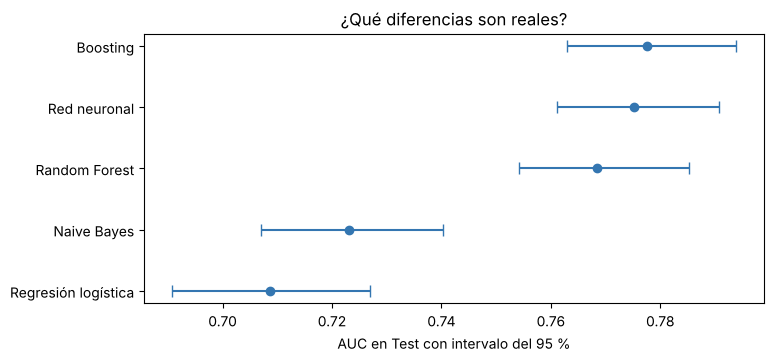

Random Forest - Red neuronal: -0.0067 · IC 95 %: [-0.0145, +0.0006] · el bosque gana en el 4% de los sorteos
Random Forest - Logística   : +0.0600 · IC 95 %: [+0.0462, +0.0747] · el bosque gana en el 100% de los sorteos


,AUC en Test,IC 95 % bajo,IC 95 % alto
Regresión logística,0.709,0.691,0.727
Naive Bayes,0.723,0.707,0.740
Random Forest,0.768,0.754,0.785
Red neuronal,0.775,0.761,0.791
Boosting,0.778,0.763,0.794


In [14]:
generador = np.random.default_rng(42)
y_real = y_test.values
sorteos = [generador.integers(0, len(y_real), len(y_real)) for _ in range(500)]     # 500 "otros Test"

auc_sorteos = pd.DataFrame({nombre: [roc_auc_score(y_real[filas], prob[filas]) for filas in sorteos]
                            for nombre, prob in prob_test.items()})

intervalos = pd.DataFrame({'AUC en Test': {nombre: roc_auc_score(y_real, prob) for nombre, prob in prob_test.items()},
                           'IC 95 % bajo': auc_sorteos.quantile(0.025), 'IC 95 % alto': auc_sorteos.quantile(0.975)}).sort_values('AUC en Test')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(intervalos['AUC en Test'], intervalos.index, xerr=[intervalos['AUC en Test'] - intervalos['IC 95 % bajo'], intervalos['IC 95 % alto'] - intervalos['AUC en Test']],
            fmt='o', color='#3476B1', capsize=4)
ax.set_xlabel('AUC en Test con intervalo del 95 %'); ax.set_title('¿Qué diferencias son reales?')
plt.show()

# La diferencia entre los dos mejores, sorteo por sorteo
diferencia = auc_sorteos['Random Forest'] - auc_sorteos['Red neuronal']
print(f'Random Forest - Red neuronal: {diferencia.mean():+.4f} · IC 95 %: [{diferencia.quantile(0.025):+.4f}, {diferencia.quantile(0.975):+.4f}] · el bosque gana en el {(diferencia > 0).mean():.0%} de los sorteos')
diferencia_log = auc_sorteos['Random Forest'] - auc_sorteos['Regresión logística']
print(f'Random Forest - Logística   : {diferencia_log.mean():+.4f} · IC 95 %: [{diferencia_log.quantile(0.025):+.4f}, {diferencia_log.quantile(0.975):+.4f}] · el bosque gana en el {(diferencia_log > 0).mean():.0%} de los sorteos')
intervalos.round(3)

**Lectura:**

- Los intervalos de **Random Forest (0.754 a 0.785), red neuronal (0.761 a 0.791) y boosting (0.763 a 0.794) se solapan casi por completo**. Con 6 000 clientes, el AUC de cada modelo tiene una incertidumbre de más o menos 0.015.
- **Bosque contra red:** la red queda por encima en el 96 % de los sorteos, pero por menos de 0.01 de AUC. Hay una diferencia pequeña a favor de la red en este Test; no cambia ninguna decisión.
- **Bosque contra logística:** la diferencia es de 0.06 y el bosque gana en el 100 % de los sorteos. **Esa diferencia sí es real.**

**Para comunicar:** "los tres modelos avanzados rinden igual, dentro del margen de error, y los tres superan claramente a la regresión logística y a la regla actual". Decir "el boosting es el mejor porque tiene 0.778 y la red 0.775" sería leer ruido.

## 4.4 El costo de cada error decide el umbral

La relación de costos "5 a 1" era un supuesto. ¿Qué pasa si cambia? Calculamos, para el Random Forest, el costo total en el Test con todos los umbrales posibles y tres relaciones de costo.

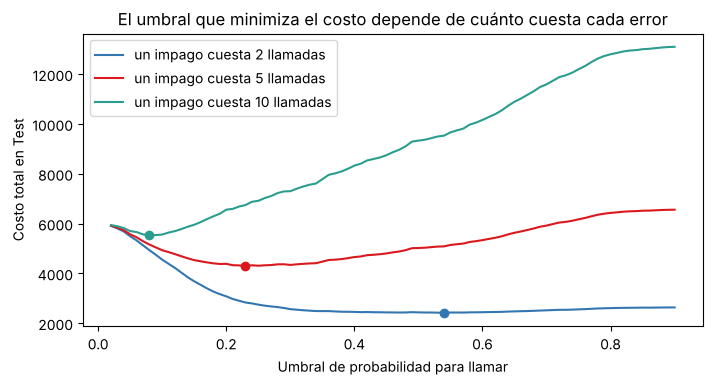

,Umbral teórico (1 / costo),Mejor umbral en Test,Clientes llamados,Impagos alcanzados
Costo del impago (en llamadas),,,,
2,0.5,0.54,642,0.33
5,0.2,0.23,1856,0.63
10,0.1,0.08,4785,0.94


In [15]:
umbrales = np.arange(0.02, 0.91, 0.01)
prob_bosque = prob_test['Random Forest']

fig, ax = plt.subplots(figsize=(8, 3.8))
filas = []
for costo_impago, color in [(2, '#3476B1'), (5, '#DA181E'), (10, '#2A9D8F')]:
    costos = [costo_total(prob_bosque, u, 1, costo_impago) for u in umbrales]
    mejor = umbrales[int(np.argmin(costos))]
    ax.plot(umbrales, costos, color=color, label=f'un impago cuesta {costo_impago} llamadas')
    ax.plot(mejor, min(costos), 'o', color=color)
    filas.append({'Costo del impago (en llamadas)': costo_impago, 'Umbral teórico (1 / costo)': round(1 / costo_impago, 2),
                  'Mejor umbral en Test': round(mejor, 2), 'Clientes llamados': int((prob_bosque > mejor).sum()),
                  'Impagos alcanzados': round((prob_bosque > mejor)[y_real == 1].mean(), 2)})
ax.set_xlabel('Umbral de probabilidad para llamar'); ax.set_ylabel('Costo total en Test'); ax.legend()
ax.set_title('El umbral que minimiza el costo depende de cuánto cuesta cada error')
plt.show()
pd.DataFrame(filas).set_index('Costo del impago (en llamadas)')

**Lectura:**

| Si un impago cuesta... | Umbral teórico | Mejor umbral en el Test | Se llama a | Impagos alcanzados |
|---|---:|---:|---:|---:|
| 2 llamadas | 0.50 | 0.54 | 642 clientes | 33 % |
| 5 llamadas | 0.20 | 0.23 | 1 856 clientes | 63 % |
| 10 llamadas | 0.10 | 0.08 | 4 785 clientes | 94 % |

- **El mismo modelo produce tres políticas completamente distintas.** Si el impago es barato, se llama al 11 % de la cartera; si es muy caro, al 80 %.
- El umbral teórico (1 / costo) queda muy cerca del mejor umbral real en los tres casos. Eso solo ocurre porque el Random Forest está **bien calibrado** (Unidad 2).
- Con costo 2, la política óptima llama a 642 clientes y alcanza al 33 % de los impagos: casi exactamente lo que hace la regla del atraso (636 clientes, 33 %). **Una regla simple puede ser la política correcta** cuando el error que evita es barato.

**Para recordar:** el modelo entrega probabilidades; **el umbral es una decisión de política** que depende de los costos, y esos costos los conoce la institución, no el analista de datos. Presentar la tabla anterior (qué pasa con cada umbral) es más útil que presentar un único AUC.

# 5. Comunicar resultados y limitaciones (4.5)

## 5.1 Una comprobación antes de recomendar: ¿el modelo trata igual a todos los grupos?

Un modelo de riesgo decide sobre personas. Antes de recomendarlo conviene mirar si sus errores se reparten de forma parecida entre grupos. Lo comprobamos por sexo (1 = hombre, 2 = mujer) con el Random Forest y el umbral 0.20.

In [16]:
llamar = prob_bosque > 0.20
equidad = pd.DataFrame({
    'clientes': y_test.groupby(X_test['sexo']).size(),
    'tasa de impago real': y_test.groupby(X_test['sexo']).mean(),
    'fracción llamada': pd.Series(llamar, index=X_test.index).groupby(X_test['sexo']).mean(),
    'impagos alcanzados': pd.Series(llamar, index=X_test.index)[y_test == 1].groupby(X_test['sexo']).mean(),
    'buenos clientes llamados': pd.Series(llamar, index=X_test.index)[y_test == 0].groupby(X_test['sexo']).mean(),
})
equidad.index = equidad.index.map({1: 'Hombres', 2: 'Mujeres'})
equidad.round(3)

,clientes,tasa de impago real,fracción llamada,impagos alcanzados,buenos clientes llamados
sexo,,,,,
Hombres,2402,0.234,0.384,0.665,0.298
Mujeres,3598,0.213,0.358,0.678,0.272


**Lectura:**

- Los hombres impagan un poco más (23.4 % frente a 21.3 %) y el modelo llama a una fracción un poco mayor de hombres (38 % frente a 36 %): coherente.
- Lo que más importa son los **errores**: el modelo alcanza al 67 % de los impagos de hombres y al 68 % de los de mujeres, y llama innecesariamente al 30 % de los buenos clientes hombres y al 27 % de las buenas clientas. Diferencias de 1 a 3 puntos: **no hay una disparidad grande**.

Una advertencia: el modelo **usa** las columnas `sexo`, `edad` y `estado_civil`. En muchos países la regulación no permite usar esas características para decidir sobre un crédito. En un caso real habría que entrenar sin ellas y repetir esta tabla.

Este tipo de tabla debería acompañar a cualquier modelo que afecte a personas. Si las diferencias fueran grandes, habría que discutirlas **antes** de usar el modelo, no después.

## 5.2 La ficha ejecutiva

Quien decide no va a leer el notebook. Necesita **una página** que responda cinco preguntas. La celda siguiente la arma con los resultados del Test.

In [17]:
elegido = 'Random Forest'
fila = tabla_test.loc[elegido]
base = tabla_test.loc['Regla del atraso (línea base)']
ic = intervalos.loc[elegido]

ficha = f"""
FICHA EJECUTIVA · Modelo de alerta de impago de tarjetas
==========================================================
1. PROBLEMA
   Anticipar en septiembre qué clientes no pagarán en octubre, para ofrecerles un plan de pagos.

2. QUÉ SE HIZO
   Se compararon {len(prob_test)} modelos y una regla simple con 30 000 clientes
   (18 000 para entrenar, 6 000 para elegir y 6 000 que ningún modelo vio hasta la evaluación final).

3. RESULTADO (en los 6 000 clientes de evaluación)
   Modelo recomendado: {elegido}.
   - Ordena a los clientes por riesgo con un AUC de {fila['AUC']:.2f} (intervalo del 95 %: {ic['IC 95 % bajo']:.2f} a {ic['IC 95 % alto']:.2f}).
     La regla actual (2 o más meses de atraso) tiene {base['AUC']:.2f}.
   - Llamando a los clientes con más de 20 % de probabilidad ({int(fila['Clientes llamados'])} de 6 000),
     se alcanza al {fila['Impagos alcanzados']:.0%} de los impagos. La regla actual alcanza al {base['Impagos alcanzados']:.0%}.
   - Costo estimado (1 por llamada, 5 por impago no gestionado): {int(fila['Costo'])} frente a {int(base['Costo'])} de la regla actual
     ({1 - fila['Costo'] / base['Costo']:.0%} menos).

4. CUÁNTO CONFIAR
   - Las probabilidades del modelo son creíbles (calibradas): de los clientes con 30 % de riesgo, impaga cerca del 30 %.
   - La ventaja sobre la regla actual es clara. La diferencia con otros modelos avanzados es pequeña.

5. LIMITACIONES
   - Los datos son de un banco de Taiwán en 2005: el modelo no se puede trasladar a otra cartera sin reentrenarlo.
   - Predice, no explica: un atraso alto está asociado al impago, pero el modelo no dice por qué ocurre.
   - Los costos 1 y 5 son supuestos; el umbral debe fijarse con los costos reales.
   - Hay que vigilarlo: si cambia la economía o la política de cupos, su rendimiento puede caer.
"""
print(ficha)


FICHA EJECUTIVA · Modelo de alerta de impago de tarjetas
1. PROBLEMA
   Anticipar en septiembre qué clientes no pagarán en octubre, para ofrecerles un plan de pagos.

2. QUÉ SE HIZO
   Se compararon 5 modelos y una regla simple con 30 000 clientes
   (18 000 para entrenar, 6 000 para elegir y 6 000 que ningún modelo vio hasta la evaluación final).

3. RESULTADO (en los 6 000 clientes de evaluación)
   Modelo recomendado: Random Forest.
   - Ordena a los clientes por riesgo con un AUC de 0.77 (intervalo del 95 %: 0.75 a 0.79).
     La regla actual (2 o más meses de atraso) tiene 0.68.
   - Llamando a los clientes con más de 20 % de probabilidad (2211 de 6 000),
     se alcanza al 67% de los impagos. La regla actual alcanza al 33%.
   - Costo estimado (1 por llamada, 5 por impago no gestionado): 4386 frente a 5076 de la regla actual
     (14% menos).

4. CUÁNTO CONFIAR
   - Las probabilidades del modelo son creíbles (calibradas): de los clientes con 30 % de riesgo, impaga cerca del 30 %

## 5.3 Las limitaciones que siempre hay que escribir

| Limitación | Pregunta que hay que hacerse | En nuestro caso |
|---|---|---|
| **Representatividad** | ¿los datos se parecen a la población donde se usará el modelo? | Taiwán, 2005: no es la cartera de ninguna institución ecuatoriana |
| **Estabilidad en el tiempo** | ¿el patrón seguirá mañana? | una crisis cambia quién impaga (recuerda los meses anómalos de 2020) |
| **Asociación, no causa** | ¿estoy leyendo la importancia de una variable como causa? | reducir el cupo no "causa" más impago |
| **Costos supuestos** | ¿quién fijó cuánto cuesta cada error? | 1 y 5 son un ejemplo |
| **Equidad** | ¿los errores se reparten de forma parecida entre grupos? | tabla de la parte 5.1 |
| **Incertidumbre** | ¿informé un intervalo o solo un número? | intervalo del AUC por remuestreo |
| **Mantenimiento** | ¿quién lo reentrena y lo vigila? | un Random Forest es más fácil de mantener que una red |

## Para el proyecto final (Unidad 5)

Mañana presentas tu proyecto. La estructura es la de esta unidad:

1. Problema, **variable objetivo** y **línea base** (parte 1).
2. Un **modelo avanzado** del módulo (bayesiano, conjunto de árboles o red neuronal).
3. **Comparación** en datos que el modelo no vio, con **incertidumbre** (parte 4).
4. **Ficha ejecutiva** con hallazgos y limitaciones (parte 5).

El notebook `05_U5_Proyecto_Final` trae la plantilla.

## Checklist de la unidad

- [ ] ¿Definí la variable objetivo, los predictores y la línea base antes de modelar?
- [ ] ¿Recordé la tasa base antes de interpretar una alerta de anomalía?
- [ ] ¿Les puse nombre de negocio a los segmentos?
- [ ] ¿Abrí el Test una sola vez?
- [ ] ¿Informé un intervalo y no solo un número?
- [ ] ¿Elegí el umbral con los costos?
- [ ] ¿Escribí las limitaciones?